# ***PROYECTO 3***
## Derivación e integración numérica, Euler explícito  — Tema 4: Motor DC- gemelo digital y control PID 
**Métodos Numéricos · Universidad del Valle de Guatemala · Semestre II 2026**

Integrantes: Martha, Mario Betancourt, Deyler, Grettel Escobedo 23586, Diego

## Contenido de esta parte del cuaderno - trabajadas hasta ahora

1. Librerías y configuración
2. Parámetros
3. Herramientas: derivación numérica e integración numérica (las funciones)
4. Modelo del motor y simulación (RK4 y Euler)
5. Carga y validación de datos (Excel real o datos de demostración)
6. Estimación mínima de parámetros (solo lo necesario para integrar)
7. **Derivación numérica** (aplicación)
8. **Integración numérica** (aplicación)

## Nota importante grett- luego borrar, es solo para avanzar en el código 
> Si `mediciones_motor_dc.xlsx` todavía no tiene datos reales, el cuaderno genera **datos de demostración** con exactamente el mismo formato (y con la "verdad" conocida) para poder probar todo el código. Cuando el Excel tenga datos, se usan automáticamente.

## **0. Objetivos:**

General  

Específicos   

1.
2.
3.

## **1. LIBRERÍAS**

In [1]:
## Librerías y parámetros globales y herramientas

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.interpolate import CubicSpline
from scipy.integrate import simpson as simpson_scipy      # Ojooo solo para verificar mi propio Simpson
from numpy.polynomial.legendre import leggauss

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
rng = np.random.default_rng(23586)
# Herramientas,  sugerencia para las funciones de: (rk4, derivar_*, trapecio, simpson), se pueden reutilizar, pueden ir al inicio, aquí, no repartidas.



## **Carga y validación de datos**


In [2]:
## se carga el archivo Excel con los datos y se valida la que sean viables para su aplicación. 
## revisar que esté en el path correcto, si no, cambiarlo.

# Modificarlo una vez tengamos los datos de la medición del motor DC.
ARCHIVO   = Path("mediciones_motor_dc.xlsx")   # Excel con las hojas Parametros / Pruebas / Datos

# Como ahora no tiene datos: 
USAR_DEMO = None    # None = automático (demo si el Excel no tiene datos) | True = forzar demo | False = forzar Excel


L_HENRY   = 2e-3    # inductancia del devanado [H]. NO está en el Excel: medirla (LCR) o estimarla del transitorio de i(t)
K_VENTANA = 5       # ventana (en muestras) para derivar la posición del encoder; se justifica en la sección 7



### Parámetros

In [3]:
# Valores de demostración (motor "verdadero" para los datos sintéticos)
DEMO = dict(R=2.0, L=2e-3, Ke=0.05, Kt=0.05, J=2e-5, b=1e-4, tauc=5e-3,   # SI
            ppv=44.0,                   # pulsos por vuelta del eje medido (11 PPR x 4 flancos)
            masa_disco=0.05, radio_disco=0.03, fs=500.0)

def leer_hoja_parametros(archivo):
    df = pd.read_excel(archivo, sheet_name="Parametros", header=2)
    df = df.dropna(subset=["Parámetro"])
    return dict(zip(df["Parámetro"].astype(str), df["Valor"]))
# Lo que hace df es leer la hoja "Parametros" del archivo Excel, omitiendo las dos primeras filas (header=2) 
# y eliminando cualquier fila que tenga un valor NaN en "Parámetro". Luego, se crea un diccionario donde las claves
#  son los nombres de los parámetros y los valores pues los valores jeje. 

def _num(raw, clave):
    """Busca la primera fila cuyo nombre contenga `clave` y devuelve su valor numérico (NaN si no hay)."""
    for nombre, v in (raw or {}).items():
        if clave.lower() in nombre.lower():
            try:
                v = float(v)
                return v if np.isfinite(v) else np.nan
            except (TypeError, ValueError):
                return np.nan
    return np.nan

## notas: se utilizar esta función para crear lo valores con demo. 
def construir_cfg(raw):
    cfg, faltan = {}, []
    def tomar(nombre, clave, demo):
        v = _num(raw, clave)
        if not np.isfinite(v):
            faltan.append(nombre); v = demo
        cfg[nombre] = v
    tomar("R", "promedio", DEMO["R"])
    tomar("ppv", "Pulsos por vuelta", DEMO["ppv"])
    tomar("masa_disco", "Masa del disco", DEMO["masa_disco"])
    tomar("radio_disco", "Radio del disco", DEMO["radio_disco"])
    tomar("fs", "Frecuencia de muestreo", DEMO["fs"])
    cfg["L"] = L_HENRY
    cfg["J_disco"] = 0.5 * cfg["masa_disco"] * cfg["radio_disco"] ** 2     # disco sólido- Formula: J = m r^2 / 2
    return cfg, faltan
# lo que hace la funcion construir_cfg es tomar los valores de la hoja de parámetros y construir un diccionario cfg con los valores numéricos.
# esto funciona en caso de que el archivo Excel no tenga datos, en cuyo caso se usan los valores de demostración.


# lógica para leer el archivo de excel: 
raw = None
try:
    raw = leer_hoja_parametros(ARCHIVO)
    print(f"Hoja 'Parametros' leída de {ARCHIVO}")
except Exception as e:
    print(f"No se pudo leer {ARCHIVO} ({type(e).__name__}). Se usarán valores de demostración.")

cfg, faltan = construir_cfg(raw)
if faltan:
    print("IMPORTANTE: Sin dato en el Excel (se usó el valor de demo):", faltan)
print(pd.Series(cfg).to_string())


Hoja 'Parametros' leída de mediciones_motor_dc.xlsx
IMPORTANTE: Sin dato en el Excel (se usó el valor de demo): ['R', 'ppv', 'masa_disco', 'radio_disco']
R                    2
ppv                 44
masa_disco        0.05
radio_disco       0.03
fs                 500
L                0.002
J_disco       2.25e-05


## Herramientas: 

### Derivación numérica
Dados los datos $(t_j, y_j)$ , se tomó como plantemiento que es sin conocer la función.  Con $t$ posiblemente no uniforme (el micro no muestrea perfecto):
  
  Comentario: luego borrar: se utilizó lo visto durante la clase con el excel- calse 19 de oct por si lo necesitan.


### Revisar:
| Método | Fórmula en el índice $j$ | Error | ¿Causal? |
|---|---|---|---|
| Hacia adelante | $\dfrac{y_{j+k}-y_j}{t_{j+k}-t_j}$ | $O(h)$ | no |
| Hacia atrás | $\dfrac{y_j-y_{j-k}}{t_j-t_{j-k}}$ | $O(h)$ | **sí** |
| Centrada | $\dfrac{y_{j+k}-y_{j-k}}{t_{j+k}-t_{j-k}}$ | $O(h^2)$ | no |
| Richardson | $\dfrac{4\,D_1-D_2}{3}$, con $D_1,D_2$ centradas de paso $h$ y $2h$ | $O(h^4)$ | no |

- **Hacia atrás con ventana $k$** es el "conteo en ventana" del enunciado: $\hat\omega_j=\dfrac{\theta_j-\theta_{j-k}}{t_j-t_{j-k}}$. Es la única opción que se puede usar *en línea* para el PID.
- Richardson es exactamente "4/3 de los vecinos cercanos − 1/3 de los lejanos" del Excel. Aquí queda **alineado en el mismo índice $j$** que la centrada.
- Todos devuelven `NaN` en los bordes donde no hay vecinos.

#Nota de grett: revisar si mi suposicióin de que se verifica que sea una función diferenciable y por ente que sea funciones analíticas realmetne si aplica. 
ultimo tema de Ecus 2 btw


## **Modelación - Ecuaciones diferenciales**


In [4]:
## Modelación de las ecuaciones a utilizar
## Ecuaciones en LaTeX, hipótesis (por ejemplo, fricción viscosa más Coulomb) y definición del vector de estado.
# ---------------- DERIVACIÓN NUMÉRICA (datos tabulados, t no necesariamente uniforme) ----------------
def d_adelante_k(t, y, k=1):
    d = np.full(len(y), np.nan)
    d[:-k] = (y[k:] - y[:-k]) / (t[k:] - t[:-k])
    return d

def d_atras_k(t, y, k=1):
    d = np.full(len(y), np.nan)
    d[k:] = (y[k:] - y[:-k]) / (t[k:] - t[:-k])
    return d

def d_centrada_k(t, y, k=1):
    d = np.full(len(y), np.nan)
    d[k:-k] = (y[2*k:] - y[:-2*k]) / (t[2*k:] - t[:-2*k])
    return d

def d_adelante(t, y): return d_adelante_k(t, y, 1)
def d_atras(t, y):    return d_atras_k(t, y, 1)
def d_centrada(t, y): return d_centrada_k(t, y, 1)

def d_richardson(t, y):
    """(4/3)·D(h) − (1/3)·D(2h), con D = diferencia centrada. Supone paso casi uniforme."""
    return (4.0 * d_centrada_k(t, y, 1) - d_centrada_k(t, y, 2)) / 3.0

METODOS_D = {"adelante": d_adelante, "atrás": d_atras, "centrada": d_centrada, "Richardson": d_richardson}

def omega_completa(d, k=None):
    """Velocidad angular [rad/s] a partir de θ(t) del encoder, sin NaN en los bordes.
    Centrada con ventana k en el interior; adelante/atrás (misma ventana) en los extremos."""
    k = k or K_VENTANA
    t, th = d["t"].to_numpy(), d["theta"].to_numpy()
    w = d_centrada_k(t, th, k)
    wf, wa = d_adelante_k(t, th, k), d_atras_k(t, th, k)
    return np.where(np.isnan(w), np.where(np.isnan(wf), wa, wf), w)

## Para integración Numérica
Se integran señales muestreadas $y_j=y(t_j)$ (potencia, corriente², etc.):

- **Trapecio compuesto** (admite $t$ no uniforme): $\displaystyle\int y\,dt\approx\sum_j \frac{y_j+y_{j+1}}{2}(t_{j+1}-t_j)$
- **Simpson 1/3 compuesto** para malla no uniforme. Para cada par de subintervalos de anchos $h_1,h_2$:
$$\int_{t_0}^{t_2} y\,dt\approx\frac{h_1+h_2}{6}\left[\Big(2-\tfrac{h_2}{h_1}\Big)y_0+\frac{(h_1+h_2)^2}{h_1h_2}\,y_1+\Big(2-\tfrac{h_1}{h_2}\Big)y_2\right]$$
(si $h_1=h_2=h$ se reduce a $\tfrac{h}{3}(y_0+4y_1+y_2)$). Si el número de subintervalos es impar, el último se cierra con trapecio.
- **Gauss–Legendre** sobre un **trazador cúbico** de los datos se construye $S(t)$ y se integra con $m$ nodos por subintervalo.

#### Notas de grett:
Tomé inspo de la vez que se realizó la hoja de trabajo de la cuerda. Deben haber otras manera de hacerlo también pero eso lo dejamos para después.


In [5]:
# ---------------- INTEGRACIÓN NUMÉRICA ----------------
def trapecio(t, y):
    return float(np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(t)))

def trapecio_acum(t, y):
    """Integral acumulada ∫_{t0}^{t_j} y dt (útil para graficar energía vs tiempo)."""
    return np.concatenate([[0.0], np.cumsum(0.5 * (y[1:] + y[:-1]) * np.diff(t))])

def simpson_compuesto(t, y):
    """Simpson 1/3 para malla no uniforme (pares de subintervalos)."""
    n = len(t) - 1
    m = n - (n % 2)                       # subintervalos que forman pares completos
    h = np.diff(t)
    h1, h2 = h[0:m:2], h[1:m:2]
    y0, y1, y2 = y[0:m:2], y[1:m:2], y[2:m+1:2]
    total = np.sum((h1 + h2) / 6.0 * ((2 - h2 / h1) * y0 + (h1 + h2) ** 2 / (h1 * h2) * y1 + (2 - h1 / h2) * y2))
    if n % 2:                             # sobra un subintervalo -> trapecio
        total += 0.5 * (y[-1] + y[-2]) * h[-1]
    return float(total)

def gauss_legendre_spline(t, y, m=5, n_sub=1):
    """Gauss-Legendre de m nodos sobre un trazador cúbico natural de (t, y); n_sub subdivisiones por intervalo."""
    S = CubicSpline(t, y, bc_type="natural")
    nodos, pesos = leggauss(m)
    bordes = t[:-1, None] + (t[1:] - t[:-1])[:, None] * np.linspace(0, 1, n_sub + 1)[None, :]
    a, b = bordes[:, :-1].ravel(), bordes[:, 1:].ravel()
    medio, semi = (a + b) / 2, (b - a) / 2
    puntos = medio[:, None] + semi[:, None] * nodos[None, :]
    return float(np.sum(semi[:, None] * pesos[None, :] * S(puntos)))

METODOS_I = {"Trapecio": trapecio, "Simpson 1/3": simpson_compuesto,
             "Gauss-Legendre (spline)": gauss_legendre_spline}


### Extras tipo utilidades

In [6]:
def rmse(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return float(np.sqrt(np.mean((a[m] - b[m]) ** 2)))

def estimar_fs(t):
    """Frecuencia de muestreo mediana [Hz] y jitter (desv. est. de Δt relativa a su mediana, en %)."""
    dt = np.diff(t)
    return 1.0 / np.median(dt), 100.0 * np.std(dt) / np.median(dt)



## **Modelo del motor y simulación**

Motor DC como sistema electromecánico acoplado, con estado $x=[i,\ \omega,\ \theta]$:

$$L\,\dot i = V - R\,i - K_e\,\omega,\qquad J\,\dot\omega = K_t\,i - b\,\omega - \tau_c\,\mathrm{sign}(\omega) - \tau_{carga},\qquad \dot\theta=\omega$$

Notas:
- $\mathrm{sign}(\omega)$ es discontinua y le hace daño al integrador cerca de $\omega=0$. Se usa la versión suavizada $\tanh(\omega/\varepsilon)$ con $\varepsilon=0.5$ rad/s.
- **Desaceleración libre:** se asume que al "cortar el voltaje" el puente H deja el devanado **abierto** (*coast*): $i=0$ y solo actúa la fricción. Si el puente frena (devanado en corto), hay que cambiar esta hipótesis; Más adelante hay una verificación de corriente medida. Revisar
- **Euler** y **RK4** comparten la misma función `f_motor`. Aquí se usan solo para generar datos sintéticos con verdad conocida (y comprobar derivación/integración). Por ahora, realmente solo es un adelanto.


In [7]:
import math

P_VERDAD = dict(R=DEMO["R"], L=DEMO["L"], Ke=DEMO["Ke"], Kt=DEMO["Kt"], J=DEMO["J"],
                b=DEMO["b"], tauc=DEMO["tauc"], tau_carga=0.0, eps=0.5)

def f_motor(x, V, P, coast=False):
    """Derivada del estado x = [i, ω, θ]. coast=True: devanado abierto (i = 0)."""
    i, w, th = x
    fric = P["b"] * w + P["tauc"] * math.tanh(w / P["eps"])
    if coast:
        return np.array([0.0, -(fric + P["tau_carga"]) / P["J"], w])
    di = (V - P["R"] * i - P["Ke"] * w) / P["L"]
    dw = (P["Kt"] * i - fric - P["tau_carga"]) / P["J"]
    return np.array([di, dw, w])

def paso_euler(x, V, P, h, coast):
    return x + h * f_motor(x, V, P, coast)

def paso_rk4(x, V, P, h, coast):
    k1 = f_motor(x, V, P, coast)
    k2 = f_motor(x + 0.5 * h * k1, V, P, coast)
    k3 = f_motor(x + 0.5 * h * k2, V, P, coast)
    k4 = f_motor(x + h * k3, V, P, coast)
    return x + h / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)

def simular(P, t_eval, V_fun, x0=(0.0, 0.0, 0.0), metodo="rk4", h_max=2e-4, t_corte=None):
    """Integra el motor y devuelve una matriz (len(t_eval), 3) con columnas [i, ω, θ].
    V_fun(t): voltaje aplicado. t_corte: instante en que se abre el circuito (desaceleración libre)."""
    paso = paso_rk4 if metodo == "rk4" else paso_euler
    x = np.array(x0, float)
    out = np.empty((len(t_eval), 3)); out[0] = x
    for k in range(len(t_eval) - 1):
        t0, t1 = t_eval[k], t_eval[k + 1]
        n = max(1, int(np.ceil((t1 - t0) / h_max))); h = (t1 - t0) / n
        for j in range(n):
            t = t0 + j * h
            coast = (t_corte is not None) and (t >= t_corte)
            if coast and x[0] != 0.0:
                x = x.copy(); x[0] = 0.0       # al abrir el circuito la corriente cae a 0
            x = paso(x, V_fun(t), P, h, coast)
        out[k + 1] = x
    return out


ω estacionaria analítica = 107.407 rad/s | RK4 = 107.407 | Euler = 107.407


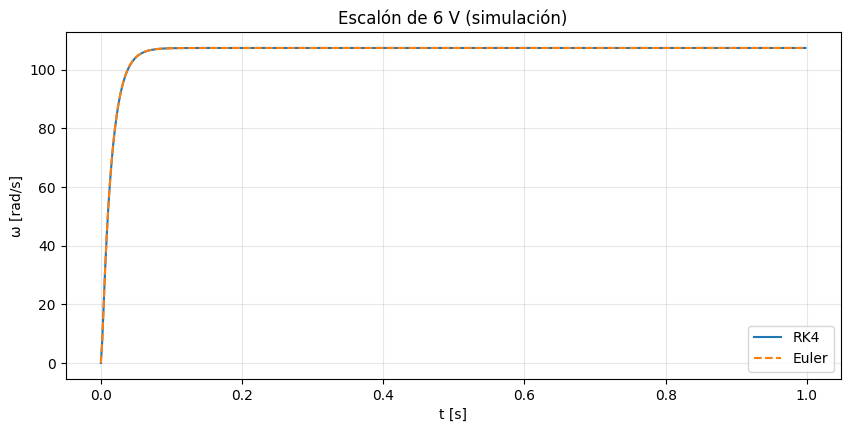

In [8]:
# Verificación rápida del simulador: escalón de 6 V, comparación contra el estacionario analítico
P, Vt = P_VERDAD, 6.0
t = np.arange(0, 1.0, 0.002)
X_rk4 = simular(P, t, lambda s: Vt, metodo="rk4")
X_eul = simular(P, t, lambda s: Vt, metodo="euler")
w_ss = (P["Kt"] * Vt / P["R"] - P["tauc"]) / (P["b"] + P["Kt"] * P["Ke"] / P["R"])      # (tanh ≈ 1)
print(f"ω estacionaria analítica = {w_ss:.3f} rad/s | RK4 = {X_rk4[-1,1]:.3f} | Euler = {X_eul[-1,1]:.3f}")

plt.plot(t, X_rk4[:, 1], label="RK4"); plt.plot(t, X_eul[:, 1], "--", label="Euler")
plt.xlabel("t [s]"); plt.ylabel("ω [rad/s]"); plt.title("Escalón de 6 V (simulación)"); plt.legend(); plt.show()



## Carga y validación de datos

Formato esperado con Excel (hoja `Datos`): una fila por muestra con **ID prueba, tiempo (s), V aplicado (V), corriente (A), pulsos acumulados**. La posición se calcula aquí como
$$\theta=\frac{\text{pulsos}}{\text{pulsos por vuelta}}\,2\pi .$$
Las filas marcadas `EJEMPLO` se ignoran. Si no hay datos reales se generan **datos de demostración**: se simula el motor, se agrega ruido a $V$ e $i$, *jitter* al tiempo y se **cuantiza** $\theta$ a la resolución del encoder.

In [9]:
def inferir_meta(id_):
    u = id_.upper()
    return dict(tipo="Escalón" if u.startswith("E") else "Desaceleración libre",
                carga="Con disco" if "CC" in u else "Sin carga", Vnom=np.nan)

def cargar_datos_excel(archivo, cfg):
    d = pd.read_excel(archivo, sheet_name="Datos")
    d = d.rename(columns={"ID prueba": "id", "Tiempo (s)": "t", "V aplicado (V)": "V", "Corriente (A)": "i",
                          "Pulsos encoder (acumulados)": "pulsos", "Notas": "notas"})
    d = d[["id", "t", "V", "i", "pulsos", "notas"]]
    d = d[~d["notas"].astype(str).str.contains("EJEMPLO", case=False, na=False)]
    d = d.dropna(subset=["id", "t", "V", "i", "pulsos"])
    if d.empty:
        return {}, pd.DataFrame()
    d["theta"] = d["pulsos"] / cfg["ppv"] * 2 * np.pi
    tests = {k: g.drop(columns=["id", "notas"]).reset_index(drop=True) for k, g in d.groupby("id", sort=False)}
    try:
        m = pd.read_excel(archivo, sheet_name="Pruebas", header=2)
        m = m.rename(columns={"ID prueba": "id", "Tipo": "tipo", "Carga": "carga", "Voltaje nominal (V)": "Vnom",
                              "Frecuencia muestreo real (Hz)": "fs", "Duración (s)": "dur"}).dropna(subset=["id"])
        m = m.set_index("id")
    except Exception:
        m = pd.DataFrame()
    filas = []
    for k in tests:
        base = inferir_meta(k)
        if k in m.index:
            for c in ("tipo", "carga", "Vnom"):
                if c in m.columns and pd.notna(m.loc[k, c]):
                    base[c] = m.loc[k, c]
        base["id"] = k
        filas.append(base)
    return tests, pd.DataFrame(filas).set_index("id")

def simular_prueba(P, ppv, V_fun, t_fin, fs, t_corte=None, jitter=20e-6, ruido_V=0.01, ruido_i=0.015):
    """Una prueba sintética con el mismo formato que el Excel (+ columnas de 'verdad': omega_true, theta_true, i_true)."""
    n = int(round(t_fin * fs)) + 1
    t = np.arange(n) / fs + rng.normal(0, jitter, n)
    t[0] = 0.0
    X = simular(P, t, V_fun, t_corte=t_corte)
    th = X[:, 2]
    d = pd.DataFrame(dict(t=t,
                          V=np.array([V_fun(s) for s in t]) + rng.normal(0, ruido_V, n),
                          i=X[:, 0] + rng.normal(0, ruido_i, n),
                          pulsos=np.floor(th * ppv / (2 * np.pi)).astype(int)))
    d["theta"] = d["pulsos"] / ppv * 2 * np.pi
    d["omega_true"], d["theta_true"], d["i_true"] = X[:, 1], th, X[:, 0]
    return d

def generar_demo(cfg, P_verdad, fs=500.0):
    plan = []
    for carga, cc in (("Sin carga", "SC"), ("Con disco", "CC")):
        plan += [(f"E_{cc}_{k}", "Escalón", carga, V) for k, V in enumerate([3, 6, 9, 12], 1)]
        plan += [(f"D_{cc}_{k}", "Desaceleración libre", carga, V) for k, V in enumerate([6, 12], 1)]
    tests, filas = {}, []
    for id_, tipo, carga, Vn in plan:
        P = dict(P_verdad)
        if carga == "Con disco":
            P["J"] += cfg["J_disco"]
        if tipo == "Escalón":
            V_fun = (lambda s, Vn=Vn: Vn if s >= 0.1 else 0.0); t_fin, t_corte = 1.6, None
        else:
            V_fun = (lambda s, Vn=Vn: Vn if s < 1.2 else 0.0);  t_fin, t_corte = 2.0, 1.2
        tests[id_] = simular_prueba(P, cfg["ppv"], V_fun, t_fin, fs, t_corte)
        filas.append(dict(id=id_, tipo=tipo, carga=carga, Vnom=Vn))
    return tests, pd.DataFrame(filas).set_index("id")

def validar_tests(tests):
    filas = []
    for k, d in tests.items():
        t = d["t"].to_numpy(); prob = []
        if np.any(np.diff(t) <= 0): prob.append("t no creciente")
        if d[["t", "V", "i", "pulsos"]].isna().any().any(): prob.append("hay NaN")
        if np.any(np.diff(d["pulsos"]) < 0): prob.append("pulsos decrecen")
        fs, jit = estimar_fs(t)
        filas.append(dict(id=k, n=len(d), dur_s=t[-1] - t[0], fs_Hz=fs, jitter_pct=jit,
                          V_max=d["V"].max(), i_max=d["i"].max(), pulsos_fin=int(d["pulsos"].iloc[-1]),
                          estado="; ".join(prob) or "OK"))
    return pd.DataFrame(filas).set_index("id")

def graficar_prueba(d, titulo=""):
    fig, ax = plt.subplots(3, 1, sharex=True, figsize=(10, 7))
    ax[0].plot(d["t"], d["V"]);                       ax[0].set_ylabel("V aplicado [V]")
    ax[1].plot(d["t"], d["i"]);                       ax[1].set_ylabel("Corriente [A]")
    ax[2].step(d["t"], d["pulsos"], where="post");    ax[2].set_ylabel("Pulsos acumulados")
    ax[2].set_xlabel("t [s]"); fig.suptitle(titulo); plt.tight_layout(); plt.show()
    

In [10]:
# ----Revisar: posteriormente, aquí se puede agregar la lógica para elegir la fuente de datos: Excel real o demostración.

tests_x, meta_x = {}, None
try:
    tests_x, meta_x = cargar_datos_excel(ARCHIVO, cfg)
except Exception as e:
    print(f"No se pudieron leer datos de {ARCHIVO} ({type(e).__name__}: {e})")

usar_demo = (len(tests_x) == 0) if USAR_DEMO is None else USAR_DEMO
if usar_demo:
    print("► Usando DATOS DE DEMOSTRACIÓN (simulados). Se ignoran los parámetros del Excel.")
    cfg = dict(R=DEMO["R"], ppv=DEMO["ppv"], masa_disco=DEMO["masa_disco"], radio_disco=DEMO["radio_disco"],
               fs=DEMO["fs"], L=DEMO["L"], J_disco=0.5 * DEMO["masa_disco"] * DEMO["radio_disco"] ** 2)
    tests, meta = generar_demo(cfg, P_VERDAD, fs=cfg["fs"])
else:
    print(f"► Usando datos reales de {ARCHIVO}: {len(tests_x)} pruebas.")
    tests, meta = tests_x, meta_x

display(meta)
resumen = validar_tests(tests)
display(resumen)
assert (resumen["estado"] == "OK").all(), "Hay pruebas con problemas: revisar la columna 'estado'"
if (resumen["fs_Hz"] < 450).any():
    print(" Alguna prueba muestrea a menos de ~500 Hz; la derivación del encoder será más ruidosa.")


/opt/pyvenv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


► Usando DATOS DE DEMOSTRACIÓN (simulados). Se ignoran los parámetros del Excel.


,tipo,carga,Vnom
id,,,
E_SC_1,Escalón,Sin carga,3
E_SC_2,Escalón,Sin carga,6
E_SC_3,Escalón,Sin carga,9
E_SC_4,Escalón,Sin carga,12
D_SC_1,Desaceleración libre,Sin carga,6
D_SC_2,Desaceleración libre,Sin carga,12
E_CC_1,Escalón,Con disco,3
E_CC_2,Escalón,Con disco,6
E_CC_3,Escalón,Con disco,9


,n,dur_s,fs_Hz,jitter_pct,V_max,i_max,pulsos_fin,estado
id,,,,,,,,
E_SC_1,801,1.59998,499.993,1.39597,3.03348,1.28862,539,OK
E_SC_2,801,1.59997,499.972,1.44648,6.03173,2.59849,1116,OK
E_SC_3,801,1.6,500.268,1.4714,9.02965,3.89717,1694,OK
E_SC_4,801,1.60004,499.763,1.42898,12.0314,5.16017,2272,OK
D_SC_1,1001,2,500.06,1.43578,6.03297,2.57858,961,OK
D_SC_2,1001,2.00001,500.096,1.481,12.0347,5.16843,2002,OK
E_CC_1,801,1.59997,499.952,1.33558,3.0316,1.37523,533,OK
E_CC_2,801,1.6,500.024,1.46364,6.028,2.75357,1104,OK
E_CC_3,801,1.6,500.387,1.42928,9.03136,4.14662,1675,OK


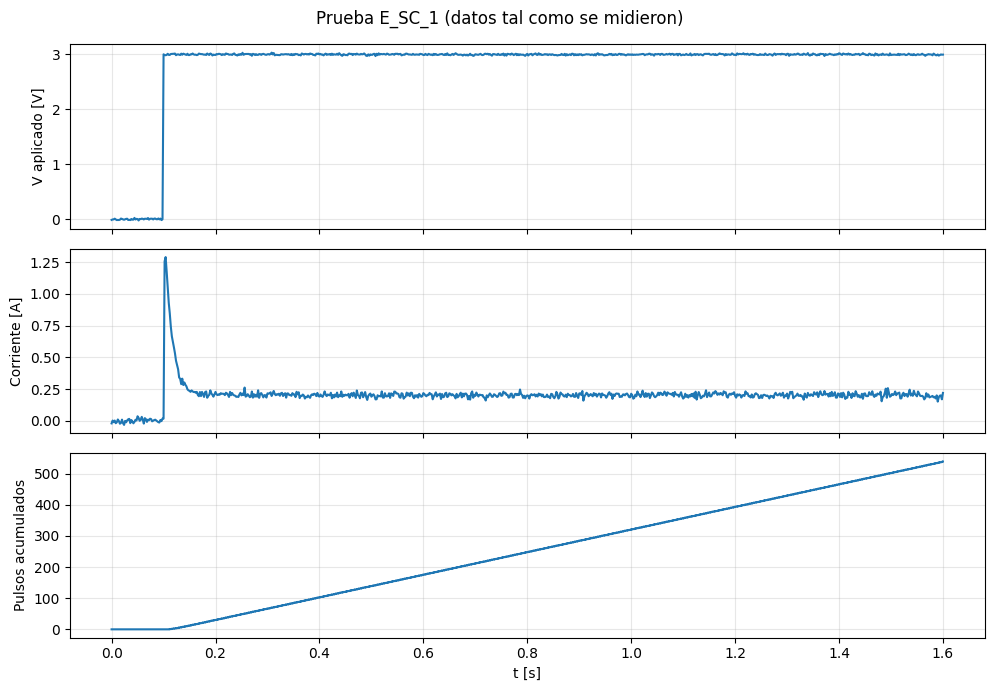

In [11]:
id_ej = next(k for k in tests if meta.loc[k, "tipo"] == "Escalón")
graficar_prueba(tests[id_ej], f"Prueba {id_ej} (datos tal como se midieron)")

## Dios bendiga las gráficas de jupyter. jaja
## si quieren ahi le cambian colorcitos más adelante. 


### 6. Estimación mínima de parámetros
OJO, esto essolo lo necesario para la integración (balance de energía) y para tener un modelo contra el cual comparar. Revisar más adelante con la animación.

1. **$K_e$** (con $K_t=K_e$ en SI): en estado estacionario $V-Ri=K_e\,\omega$ mínimos cuadrados con los escalones de distinto voltaje.
2. **$b$ y $\tau_c$**: en estacionario $K_t\,i=b\,\omega+\tau_c$  recta de $K_t\,i$ contra $\omega$ (pendiente $b$, intercepto $\tau_c$).
3. **$J$** con la **forma integral** (sin derivar dos veces). En la desaceleración libre $J\dot\omega=-b\omega-\tau_c$; integrando desde el corte $t_c$ hasta que se detiene ($\omega=0$):
$$J\,\omega_1 = b\,\Delta\theta+\tau_c\,\Delta t \quad\Rightarrow\quad J=\frac{b\,\Delta\theta+\tau_c\,\Delta t}{\omega_1}$$
con $\omega_1$ la velocidad estacionaria justo antes del corte. Con y sin disco: $J_{disco}=J_{CC}-J_{SC}$, que se compara con $\tfrac12 m r^2$.

In [12]:
def regimen_estacionario(tests, meta, frac=0.2):
    filas = []
    for id_, d in tests.items():
        if meta.loc[id_, "tipo"] != "Escalón":
            continue
        t, th = d["t"].to_numpy(), d["theta"].to_numpy()
        j0 = int(len(d) * (1 - frac))
        filas.append(dict(id=id_, carga=meta.loc[id_, "carga"],
                          V=d["V"].iloc[j0:].mean(), i=d["i"].iloc[j0:].mean(),
                          w=(th[-1] - th[j0]) / (t[-1] - t[j0])))
    return pd.DataFrame(filas).set_index("id")

def estimar_J(d, b, tauc, T_ss=0.3):
    t, V, th, p = (d[c].to_numpy() for c in ("t", "V", "theta", "pulsos"))
    jc = np.where(V > 0.5 * V.max())[0][-1] + 1          # primera muestra después del corte
    m = (t >= t[jc - 1] - T_ss) & (t <= t[jc - 1])
    j_ini = np.where(m)[0][0]
    w1 = (th[jc - 1] - th[j_ini]) / (t[jc - 1] - t[j_ini])  # velocidad estacionaria antes del corte
    j_stop = np.where(np.diff(p) != 0)[0].max() + 1          # última muestra en que cambió el conteo
    dth, dt = th[j_stop] - th[jc - 1], t[j_stop] - t[jc - 1]
    i = d["i"].to_numpy()
    i_pre = np.mean(np.abs(i[j_ini:jc])); i_post = np.mean(np.abs(i[jc:]))
    return (b * dth + tauc * dt) / w1, dict(t_corte=t[jc], w1=w1, t_paro=t[j_stop], frena=bool(i_post > 0.1 * i_pre))

ss = regimen_estacionario(tests, meta)
display(ss)

R, L = cfg["R"], cfg["L"]
Ke = np.sum(ss["w"] * (ss["V"] - R * ss["i"])) / np.sum(ss["w"] ** 2)
A = np.column_stack([ss["w"].to_numpy(), np.ones(len(ss))])
(b_est, tauc_est), *_ = np.linalg.lstsq(A, Ke * ss["i"].to_numpy(), rcond=None)

J_por_carga = {}
for id_, d in tests.items():
    if meta.loc[id_, "tipo"] == "Escalón":
        continue
    J, info = estimar_J(d, b_est, tauc_est)
    if info["frena"]:
        print(f"⚠ {id_}: la corriente medida después del corte NO es ~0 (el puente H parece frenar). "
              "La estimación de J supone devanado abierto.")
    J_por_carga.setdefault(meta.loc[id_, "carga"], []).append(J)
J_por_carga = {c: float(np.mean(v)) for c, v in J_por_carga.items()}

J_sc = J_por_carga.get("Sin carga", np.nan)
J_cc = J_por_carga.get("Con disco", J_sc + cfg["J_disco"])
P_est = dict(R=R, L=L, Ke=Ke, Kt=Ke, J=J_sc, b=b_est, tauc=tauc_est, tau_carga=0.0, eps=0.5)

tabla = pd.DataFrame({"estimado": {"Ke=Kt [V·s/rad]": Ke, "b [N·m·s/rad]": b_est, "τc [N·m]": tauc_est,
                                   "J sin carga [kg·m²]": J_sc, "J con disco [kg·m²]": J_cc,
                                   "J disco = J_CC − J_SC": J_cc - J_sc}})
tabla["referencia"] = [P_VERDAD["Ke"] if usar_demo else np.nan, P_VERDAD["b"] if usar_demo else np.nan,
                       P_VERDAD["tauc"] if usar_demo else np.nan, P_VERDAD["J"] if usar_demo else np.nan,
                       P_VERDAD["J"] + cfg["J_disco"] if usar_demo else np.nan, cfg["J_disco"]]
tabla.columns = ["estimado", "referencia (verdad demo / ½·m·r²)"]
display(tabla)


,carga,V,i,w
id,,,,
E_SC_1,Sin carga,3.00001,0.203402,51.7709
E_SC_2,Sin carga,5.99909,0.312749,107.12
E_SC_3,Sin carga,8.99954,0.427186,162.866
E_SC_4,Sin carga,11.9994,0.537569,218.635
E_CC_1,Con disco,3.00049,0.203819,52.2122
E_CC_2,Con disco,5.9994,0.314734,107.543
E_CC_3,Con disco,9.0003,0.423954,162.894
E_CC_4,Con disco,12.0012,0.539537,218.636


,estimado,referencia (verdad demo / ½·m·r²)
Ke=Kt [V·s/rad],0.04999,0.05
b [N·m·s/rad],0.000100494,0.0001
τc [N·m],0.00492704,0.005
J sin carga [kg·m²],1.9537e-05,2e-05
J con disco [kg·m²],4.22205e-05,4.25e-05
J disco = J_CC − J_SC,2.26835e-05,2.25e-05


## Derivación Numerica:
Verificación de las funciones con una función conocida para nosotros. 
Mismo experimento del Excel de clase ($y=\sin x$, $y'=\cos x$): el error máximo debe bajar como $h^p$ con $p=1$ (adelante/atrás), $p=2$ (centrada) y $p=4$ (Richardson).

In [13]:
def verificar_derivadas(hs=(0.2, 0.1, 0.05)):
    filas = []
    for h in hs:
        x = np.arange(0, 6 + h / 2, h); y = np.sin(x); ref = np.cos(x)
        filas.append({"h": h, **{nom: np.nanmax(np.abs(f(x, y) - ref)) for nom, f in METODOS_D.items()}})
    err = pd.DataFrame(filas).set_index("h")
    orden = pd.DataFrame(np.log2(err.iloc[:-1].to_numpy() / err.iloc[1:].to_numpy()),
                         index=err.index[:-1], columns=err.columns)
    return err, orden

err_d, orden_d = verificar_derivadas()
print("Error máximo |D − cos(x)|"); display(err_d)
print("Orden observado p (≈ 1, 1, 2, 4)"); display(orden_d)


Error máximo |D − cos(x)|


,adelante,atrás,centrada,Richardson
h,,,,
0.2,0.0997845,0.099867,0.006642,5.29894e-05
0.1,0.0499752,0.0499857,0.00166439,3.32649e-06
0.05,0.0249981,0.0249963,0.0004166,2.08264e-07


Orden observado p (≈ 1, 1, 2, 4)


,adelante,atrás,centrada,Richardson
h,,,,
0.2,0.997605,0.998493,1.99662,3.99363
0.1,0.999395,0.999801,1.99826,3.99751


#### Experimento con "verdad" conocida: ruido de cuantización vs el retraso
El encoder entrega $\theta$ **cuantizada** (un pulso = $2\pi/\text{pulsos por vuelta}$ rad). Se simula un escalón de 12 V con el modelo, se cuantiza $\theta$ y se compara cada derivada con la $\omega$ verdadera en dos zonas:

- **Transitorio** (justo después del escalón): una ventana grande **suaviza/retrasa** la subida error alto.
- **Estacionario**: una ventana chica deja pasar el **ruido de cuantización**- error alto.

El tamaño de ventana $k$ es el compromiso entre ambos.

Richardson (k=1): RMSE transitorio = 14.546 | estacionario = 13.799 rad/s


,rmse_atras_trans,rmse_atras_est,rmse_centrada_trans,rmse_centrada_est
k,,,,
1,20.6361,16.727,11.8136,11.4852
2,13.7431,11.4729,7.13624,7.5691
3,14.3012,9.07065,5.52237,5.69543
5,17.9473,6.50439,5.10655,3.47158
8,25.2632,4.43649,7.25857,0.854957
12,34.5768,2.65732,11.764,1.47129
20,50.7102,1.44047,19.7007,0.877087
30,67.2176,0.921562,28.2648,0.570568


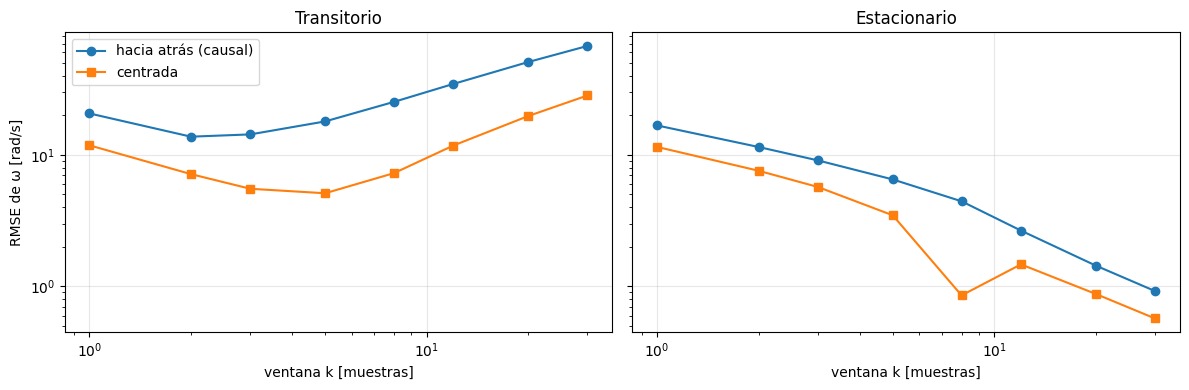

In [14]:
P_exp = P_est if np.isfinite(P_est["J"]) else P_VERDAD
d_exp = simular_prueba(P_exp, cfg["ppv"], lambda s: 12.0 if s >= 0.1 else 0.0, t_fin=1.6, fs=cfg["fs"])
t_e, th_e, w_true = d_exp["t"].to_numpy(), d_exp["theta"].to_numpy(), d_exp["omega_true"].to_numpy()
zona_tr = (t_e >= 0.1) & (t_e < 0.25)       # transitorio
zona_ss = (t_e >= 0.8)                      # estacionario

filas = []
for k in [1, 2, 3, 5, 8, 12, 20, 30]:
    w_at, w_ce = d_atras_k(t_e, th_e, k), d_centrada_k(t_e, th_e, k)
    filas.append(dict(k=k, rmse_atras_trans=rmse(w_at[zona_tr], w_true[zona_tr]), rmse_atras_est=rmse(w_at[zona_ss], w_true[zona_ss]),
                      rmse_centrada_trans=rmse(w_ce[zona_tr], w_true[zona_tr]), rmse_centrada_est=rmse(w_ce[zona_ss], w_true[zona_ss])))
tab_k = pd.DataFrame(filas).set_index("k")
w_r = d_richardson(t_e, th_e)
print(f"Richardson (k=1): RMSE transitorio = {rmse(w_r[zona_tr], w_true[zona_tr]):.3f} | estacionario = {rmse(w_r[zona_ss], w_true[zona_ss]):.3f} rad/s")
display(tab_k)

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, z, nom in zip(ax, ("trans", "est"), ("Transitorio", "Estacionario")):
    a.loglog(tab_k.index, tab_k[f"rmse_atras_{z}"], "o-", label="hacia atrás (causal)")
    a.loglog(tab_k.index, tab_k[f"rmse_centrada_{z}"], "s-", label="centrada")
    a.set_title(nom); a.set_xlabel("ventana k [muestras]")
ax[0].set_ylabel("RMSE de ω [rad/s]"); ax[0].legend(); plt.tight_layout(); plt.show()



#### Notitas para discutir de las imagenes cuando tengamos una lectura real. 
Podemos hablar sobre ¿qué $k$ da el mejor compromiso? ¿qué pasa con Richardson?  
 ¿por qué hacia atrás tiene más error en el transitorio que la centrada para el mismo $k$?)

Con el $k$ elegido se fija `K_VENTANA` en la celda de configuración. Para el **PID en línea solo sirven los métodos causales** (hacia atrás), la centrada y Richardson son para análisis offline. etc. 

#### Aplicación a las mediciones
Velocidad angular $\omega(t)$ obtenida de $\theta(t)$ con los distintos métodos, para un escalón y una desaceleración libre.

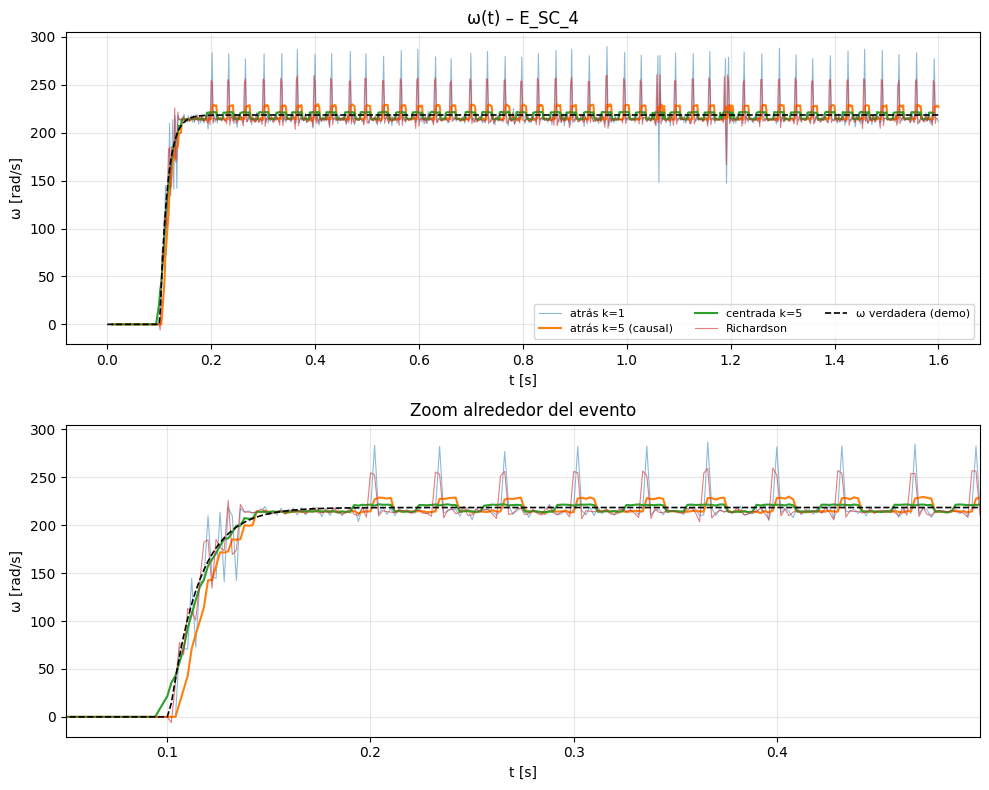

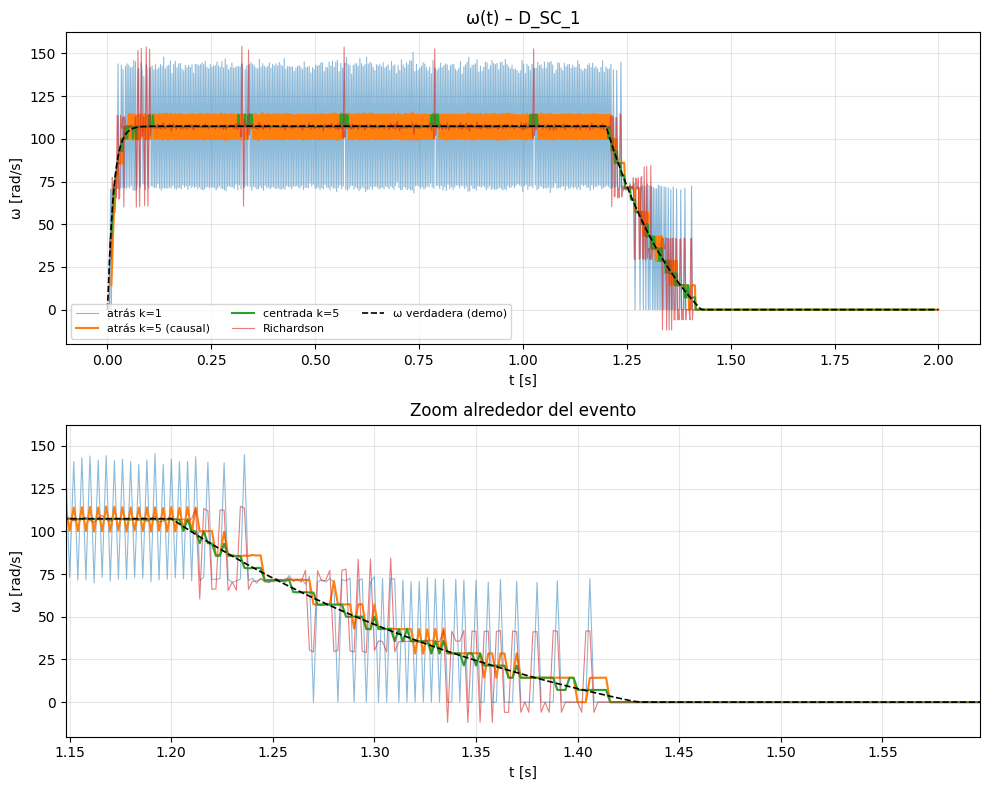

In [15]:
def graficar_omega(d, titulo, k=None):
    k = k or K_VENTANA
    t, th = d["t"].to_numpy(), d["theta"].to_numpy()
    fig, ax = plt.subplots(2, 1, figsize=(10, 8))
    for a in ax:
        a.plot(t, d_atras_k(t, th, 1), lw=0.8, alpha=0.5, label="atrás k=1")
        a.plot(t, d_atras_k(t, th, k), label=f"atrás k={k} (causal)")
        a.plot(t, d_centrada_k(t, th, k), label=f"centrada k={k}")
        a.plot(t, d_richardson(t, th), lw=0.8, alpha=0.6, label="Richardson")
        if "omega_true" in d:
            a.plot(t, d["omega_true"], "k--", lw=1.2, label="ω verdadera (demo)")
        a.set_ylabel("ω [rad/s]")
    ax[0].set_title(titulo); ax[0].legend(ncol=3, fontsize=8)
    ax[0].set_xlabel("t [s]"); ax[1].set_xlabel("t [s]")
    # zoom en el evento (subida o frenado)
    V = d["V"].to_numpy(); ev = t[np.argmax(np.abs(np.diff(V)) > 0.4 * np.abs(V).max())] if np.any(np.abs(np.diff(V)) > 0.4 * np.abs(V).max()) else t[0]
    ax[1].set_xlim(ev - 0.05, ev + 0.4); ax[1].set_title("Zoom alrededor del evento")
    plt.tight_layout(); plt.show()

id_E = max((k for k in tests if meta.loc[k, "tipo"] == "Escalón"), key=lambda k: tests[k]["V"].max())
graficar_omega(tests[id_E], f"ω(t) – {id_E}")
ids_D = [k for k in tests if meta.loc[k, "tipo"] != "Escalón"]
if ids_D:
    graficar_omega(tests[ids_D[0]], f"ω(t) – {ids_D[0]}")

    

#### discutir sobre esto con los resultado reales bueno chavos ?

## Integración numérica

### Verificación de las funciones con una integral conocida
$\int_0^\pi \sin x\,dx = 2$. El error debe bajar como $h^2$ (trapecio) y $h^4$ (Simpson); Gauss–Legendre sobre spline queda limitado por la precisión del trazador.

In [16]:
def tabla_verificacion_integral(ns=(4, 8, 16, 32, 64)):
    filas = []
    for n in ns:
        x = np.linspace(0, np.pi, n + 1); y = np.sin(x)
        filas.append(dict(n=n, **{nom: abs(f(x, y) - 2.0) for nom, f in METODOS_I.items()},
                          simpson_scipy=abs(simpson_scipy(y, x=x) - 2.0)))
    return pd.DataFrame(filas).set_index("n")

display(tabla_verificacion_integral())



,Trapecio,Simpson 1/3,Gauss-Legendre (spline),simpson_scipy
n,,,,
4,0.103881,0.00455975,0.00130658,0.00455975
8,0.0257684,0.00026917,6.97619e-05,0.00026917
16,0.00642966,1.6591e-05,4.18583e-06,1.6591e-05
32,0.00160664,1.03337e-06,2.58935e-07,1.03337e-06
64,0.000401611,6.453e-08,1.61418e-08,6.453e-08


###  Comparación de métodos sobre la energía eléctrica

Notita: $E_e=\displaystyle\int V\,i\,dt$ en una prueba. Se compara cada método contra Simpson 1/3-igual que cuando trabajamos con la cuerda-  En la demo también se muestra el valor "verdadero" calculado con la corriente sin ruido.

In [17]:
d = tests[id_E]
t, p = d["t"].to_numpy(), (d["V"] * d["i"]).to_numpy()
vals = {nom: f(t, p) for nom, f in METODOS_I.items()}
vals["Simpson (scipy, referencia)"] = float(simpson_scipy(p, x=t))
ref = vals["Simpson 1/3"]
comp = pd.DataFrame({"E_e [J]": vals})
comp["|dif| vs Simpson [J]"] = (comp["E_e [J]"] - ref).abs()
comp["dif %"] = 100 * comp["|dif| vs Simpson [J]"] / abs(ref)
display(comp)
if "i_true" in d:
    print(f"Valor 'verdadero' de la demo (V·i_true, trapecio): {trapecio(t, (d['V'] * d['i_true']).to_numpy()):.6g} J")
    

,E_e [J],|dif| vs Simpson [J],dif %
Trapecio,10.6236,0.0129576,0.121821
Simpson 1/3,10.6366,0,0
Gauss-Legendre (spline),10.624,0.0125625,0.118106
"Simpson (scipy, referencia)",10.6366,1.77636e-15,1.67004e-14


Valor 'verdadero' de la demo (V·i_true, trapecio): 10.6217 J


### Balance de energía de cada prueba
De $V\,i = R\,i^2 + \tfrac{d}{dt}\!\big(\tfrac12 L i^2\big) + K_t\,i\,\omega$ y $K_t\,i\,\omega = J\omega\dot\omega + b\,\omega^2+\tau_c|\omega|$, integrando:

$$\underbrace{\int V i\,dt}_{E_e}=\underbrace{\int R i^2dt}_{E_R}+\underbrace{\tfrac12 L\,\Delta(i^2)}_{E_L}+\underbrace{\tfrac12 J\,\Delta(\omega^2)}_{E_k}+\underbrace{\int(b\omega^2+\tau_c|\omega|)dt}_{E_{fric}}$$

El **residuo** $E_e-(E_R+E_L+E_k+E_{fric})$ esto nos permite medir mide tan bien cierra el balance (ruido, cuantización, parámetros mal estimados).

 Además:
- $\eta_{conv}=\int K_t\,i\,\omega\,dt\,/E_e$: fracción de la energía eléctrica que se convierte en energía mecánica (antes de la fricción propia).
- $\eta_{cin}=E_k/E_e$: fracción que termina como energía cinética del rotor (y del disco).

,E_e,E_R,E_L,E_k,E_fric,residuo,residuo_pct,eta_conv,eta_cin
E_SC_1,0.969672,0.163837,3.7986e-05,0.0287847,0.779737,-0.00272438,-0.280959,0.829596,0.029685
E_SC_2,3.06855,0.454297,0.000104221,0.115045,2.49806,0.00103966,0.0338812,0.851536,0.0374918
E_SC_3,6.27696,0.888619,0.000173595,0.249434,5.13429,0.00444686,0.0708441,0.858398,0.039738
E_SC_4,10.6236,1.47826,0.000287644,0.505388,8.69088,-0.0511767,-0.481725,0.860816,0.0475721
D_SC_1,2.49887,0.393241,-0.00358922,-0.0156228,2.10857,0.01627,0.651096,0.850962,-0.00625194
D_SC_2,8.68366,1.30229,-0.0144658,-0.0669964,7.41002,0.0528106,0.608161,0.858699,-0.00771523
E_CC_1,1.04034,0.211701,4.0665e-05,0.055723,0.768404,0.00447403,0.430054,0.794955,0.0535622
E_CC_2,3.32692,0.626733,9.24745e-05,0.249114,2.46064,-0.00966211,-0.290422,0.810282,0.0748783
E_CC_3,6.88456,1.28075,0.000181686,0.57765,5.05701,-0.0310308,-0.450731,0.813447,0.0839052
E_CC_4,11.7294,2.17034,0.000292542,1.01739,8.55258,-0.0111976,-0.0954661,0.814987,0.0867381


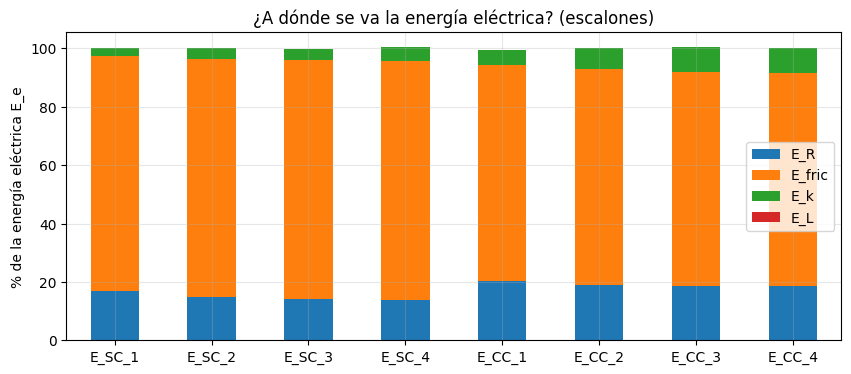

In [18]:
def balance_energia(d, P, J, k=None):
    k = k or K_VENTANA
    t, V, i = d["t"].to_numpy(), d["V"].to_numpy(), d["i"].to_numpy()
    w = omega_completa(d, k)
    E_e    = trapecio(t, V * i)
    E_R    = trapecio(t, P["R"] * i ** 2)
    E_L    = 0.5 * P["L"] * (np.mean(i[-k:]) ** 2 - np.mean(i[:k]) ** 2)
    E_k    = 0.5 * J * (np.mean(w[-k:]) ** 2 - np.mean(w[:k]) ** 2)
    E_fric = trapecio(t, P["b"] * w ** 2 + P["tauc"] * np.abs(w))
    E_conv = trapecio(t, P["Kt"] * i * w)
    resid  = E_e - (E_R + E_L + E_k + E_fric)
    return dict(E_e=E_e, E_R=E_R, E_L=E_L, E_k=E_k, E_fric=E_fric, residuo=resid,
                residuo_pct=100 * resid / E_e, eta_conv=E_conv / E_e, eta_cin=E_k / E_e)

J_de = {"Sin carga": J_sc, "Con disco": J_cc}
bal = pd.DataFrame({id_: balance_energia(d, P_est, J_de[meta.loc[id_, "carga"]]) for id_, d in tests.items()}).T
display(bal)

esc = [k for k in tests if meta.loc[k, "tipo"] == "Escalón"]
(bal.loc[esc, ["E_R", "E_fric", "E_k", "E_L"]].div(bal.loc[esc, "E_e"], axis=0) * 100).plot.bar(stacked=True, figsize=(10, 4))
plt.ylabel("% de la energía eléctrica E_e"); plt.title("¿A dónde se va la energía eléctrica? (escalones)")
plt.xticks(rotation=0); plt.show()


###  Eficiencia en función de la velocidad (régimen estacionario)
En estacionario $P_{elec}=V\,i$, $P_{Joule}=R\,i^2$ y la potencia convertida a mecánica es $K_t\,i\,\omega=K_e\,\omega\,i$, de modo que $\eta_{conv}(\omega)=K_e\,\omega/V$. Sin carga externa, toda esa potencia mecánica se gasta en fricción.

,carga,V,i,w,eta_conv,frac_Joule
id,,,,,,
E_SC_1,Sin carga,3.00001,0.203402,51.7709,0.862672,0.135601
E_SC_2,Sin carga,5.99909,0.312749,107.12,0.892621,0.104266
E_SC_3,Sin carga,8.99954,0.427186,162.866,0.904676,0.0949351
E_SC_4,Sin carga,11.9994,0.537569,218.635,0.910846,0.0895997
E_CC_1,Con disco,3.00049,0.203819,52.2122,0.869888,0.135857
E_CC_2,Con disco,5.9994,0.314734,107.543,0.896104,0.104922
E_CC_3,Con disco,9.0003,0.423954,162.894,0.904757,0.0942088
E_CC_4,Con disco,12.0012,0.539537,218.636,0.910705,0.0899136


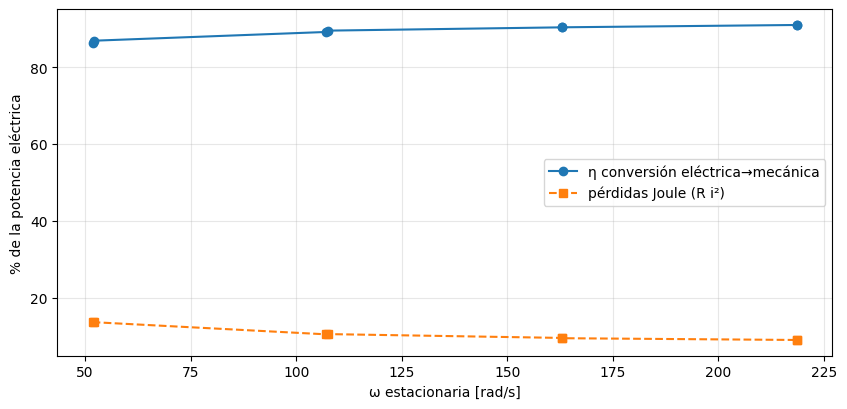

In [19]:
ss2 = ss.copy()
ss2["eta_conv"] = P_est["Ke"] * ss2["w"] / ss2["V"]
ss2["frac_Joule"] = R * ss2["i"] / ss2["V"]          # R i² / (V i)
display(ss2)

pr = ss2.sort_values("w")
plt.plot(pr["w"], 100 * pr["eta_conv"], "o-", label="η conversión eléctrica→mecánica")
plt.plot(pr["w"], 100 * pr["frac_Joule"], "s--", label="pérdidas Joule (R i²)")
plt.xlabel("ω estacionaria [rad/s]"); plt.ylabel("% de la potencia eléctrica"); plt.legend(); plt.show()


**Interpretación:** ahi le siguen con esta parte cuando tengamos resultado reales :3
puede ser de:¿cuánto vale el residuo en %? ¿qué término domina en cada nivel de voltaje? ¿cómo cambia $\eta_{cin}$ con el disco?


###  Momento de inercia del disco integrando su perfil
Para un sólido de revolución homogéneo con radio $r(z)$ a lo largo del eje, con masa $m=\rho\pi\int r^2dz$:
$$J=\frac{\pi\rho}{2}\int r(z)^4\,dz=\frac{m}{2}\,\frac{\int r(z)^4\,dz}{\int r(z)^2\,dz}$$
Para un cilindro de radio constante da $\tfrac12 m r^2$ (verificación). **Reemplazar el perfil de ejemplo** por los pares $(z_i,r_i)$ medidos del disco.


In [20]:
def inercia_perfil(z, r, masa):
    return 0.5 * masa * simpson_compuesto(z, r ** 4) / simpson_compuesto(z, r ** 2)

m_d, r_d = cfg["masa_disco"], cfg["radio_disco"]
z = np.linspace(0, 0.010, 21)                                   # [m] a lo largo del eje
r_cil = np.full_like(z, r_d)
print(f"Cilindro: J perfil = {inercia_perfil(z, r_cil, m_d):.6e} | ½·m·r² = {0.5*m_d*r_d**2:.6e} kg·m²")

# EJEMPLO de perfil con "cubo" central (REEMPLAZAR por las mediciones reales)
r_cubo = np.where(z < 0.006, r_d, 0.012)
print(f"Perfil con cubo (ejemplo): J = {inercia_perfil(z, r_cubo, m_d):.6e} kg·m²")


Cilindro: J perfil = 2.250000e-05 | ½·m·r² = 2.250000e-05 kg·m²
Perfil con cubo (ejemplo): J = 2.056154e-05 kg·m²


## Gemelo digital completo: comparación con las mediciones

La validación utiliza el voltaje registrado en cada prueba como entrada del sistema electromecánico acoplado y los parámetros `P_est` obtenidos previamente. La señal $V(t)$ se representa por retención de orden cero entre muestras, sin reemplazarla por el voltaje nominal de la prueba.

Para cada registro se integra con el método RK4 implementado en `simular`, usando un paso interno máximo de $h=2\times 10^{-4}$ s. El estado inicial se obtiene de la corriente, de la posición y de la velocidad calculada a partir del encoder. Se utiliza $J_{SC}$ para ensayos sin carga y $J_{CC}$ para ensayos con disco. En las pruebas de desaceleración se identifica el instante de corte en el voltaje registrado; el modelo de circuito abierto se aplica cuando la corriente medida después del corte es cercana a cero.

La velocidad medida se estima a partir de la posición cuantizada del encoder con la ventana `K_VENTANA`. Para comparar señales con el mismo tratamiento numérico, la posición simulada se deriva con esa misma ventana. Se reportan RMSE, MAE y error normalizado por el intervalo entre los percentiles 5 y 95 de cada señal medida. Las estimaciones de parámetros y la comparación corresponden al mismo conjunto de pruebas, por lo que representan una **validación interna del ajuste**, no una validación con datos independientes.

In [21]:
def entrada_voltaje_registrado(t, V):
    t = np.asarray(t, dtype=float)
    V = np.asarray(V, dtype=float)
    if len(t) < 2 or not np.all(np.isfinite(t)) or not np.all(np.isfinite(V)):
        raise ValueError("La prueba requiere al menos dos muestras finitas de tiempo y voltaje.")
    if not np.all(np.diff(t) > 0):
        raise ValueError("Los tiempos de la prueba deben ser estrictamente crecientes.")

    def V_fun(instante):
        j = np.searchsorted(t, instante, side="right") - 1
        return float(V[np.clip(j, 0, len(V) - 1)])

    return V_fun


def identificar_corte_voltaje(d):
    t = d["t"].to_numpy(dtype=float)
    V = d["V"].to_numpy(dtype=float)
    dt = np.median(np.diff(t))
    n_ventana = max(3, int(np.ceil(0.012 / dt)))
    amplitud = float(np.quantile(np.abs(V), 0.95))
    if amplitud < 0.2:
        return None
    activo = np.abs(V) >= max(0.15, 0.15 * amplitud)
    transiciones = np.flatnonzero(activo[:-1] & ~activo[1:]) + 1
    for j in transiciones:
        if (j >= n_ventana and j + n_ventana <= len(t)
                and np.mean(activo[j - n_ventana:j]) >= 0.8
                and np.mean(activo[j:j + n_ventana]) <= 0.1):
            return int(j)
    return None


def evaluar_desconexion(d, j_corte):
    if j_corte is None:
        return False
    t = d["t"].to_numpy(dtype=float)
    i = d["i"].to_numpy(dtype=float)
    dt = np.median(np.diff(t))
    n_pre = max(3, int(np.ceil(0.10 / dt)))
    n_post = max(3, int(np.ceil(0.08 / dt)))
    pre = np.abs(i[max(0, j_corte - n_pre):j_corte])
    post = np.abs(i[j_corte + 1:min(len(i), j_corte + 1 + n_post)])
    if not len(pre) or not len(post):
        return False
    return bool(np.median(post) <= max(0.05, 0.12 * np.median(pre)))


def indicadores_ajuste(medido, simulado):
    medido = np.asarray(medido, dtype=float)
    simulado = np.asarray(simulado, dtype=float)
    mascara = np.isfinite(medido) & np.isfinite(simulado)
    if not np.any(mascara):
        return dict(rmse=np.nan, mae=np.nan, nrmse_pct=np.nan, r2=np.nan)
    y, yh = medido[mascara], simulado[mascara]
    resid = y - yh
    rmse_val = float(np.sqrt(np.mean(resid ** 2)))
    mae_val = float(np.mean(np.abs(resid)))
    intervalo = float(np.percentile(y, 95) - np.percentile(y, 5))
    nrmse_pct = 100 * rmse_val / intervalo if intervalo > 1e-12 else np.nan
    ss_tot = float(np.sum((y - np.mean(y)) ** 2))
    r2 = 1 - float(np.sum(resid ** 2)) / ss_tot if ss_tot > 1e-12 else np.nan
    return dict(rmse=rmse_val, mae=mae_val, nrmse_pct=nrmse_pct, r2=r2)


def simular_y_comparar_prueba(id_, d, meta, P_base, J_sin_carga, J_con_disco):
    tipo = str(meta.loc[id_, "tipo"])
    carga = str(meta.loc[id_, "carga"])
    t = d["t"].to_numpy(dtype=float)
    V = d["V"].to_numpy(dtype=float)
    i_med = d["i"].to_numpy(dtype=float)
    theta_med = d["theta"].to_numpy(dtype=float)
    omega_med = omega_completa(d, K_VENTANA)
    J = J_con_disco if carga == "Con disco" else J_sin_carga
    P = dict(P_base, J=float(J))
    claves = ("R", "L", "Ke", "Kt", "J", "b", "tauc", "eps")
    if not all(np.isfinite(P[k]) for k in claves) or min(P["R"], P["L"], P["J"], P["eps"]) <= 0:
        raise ValueError(f"Parámetros de simulación no válidos en {id_}: {P}")

    j_corte = identificar_corte_voltaje(d) if tipo == "Desaceleración libre" else None
    circuito_abierto = evaluar_desconexion(d, j_corte)
    t_corte = float(t[j_corte]) if circuito_abierto else None
    x0 = (float(i_med[0]), float(omega_med[0]), float(theta_med[0]))
    X = simular(P, t, entrada_voltaje_registrado(t, V), x0=x0,
                metodo="rk4", h_max=2e-4, t_corte=t_corte)
    derivada_sim = pd.DataFrame({"t": t, "theta": X[:, 2]})
    omega_sim_encoder = omega_completa(derivada_sim, K_VENTANA)
    comparacion = pd.DataFrame({
        "t": t, "V_med": V, "i_med": i_med, "i_sim": X[:, 0],
        "omega_med": omega_med, "omega_sim": X[:, 1],
        "omega_sim_encoder": omega_sim_encoder, "theta_sim": X[:, 2]
    })
    met_w = indicadores_ajuste(omega_med, omega_sim_encoder)
    met_i = indicadores_ajuste(i_med, X[:, 0])
    fila = {
        "ID prueba": id_, "Tipo": tipo, "Carga": carga, "J [kg m²]": J,
        "Corte t [s]": float(t[j_corte]) if j_corte is not None else np.nan,
        "Modelo corte": ("Abierto" if circuito_abierto else "Eléctrico") if j_corte is not None else "Sin corte",
        "RMSE ω [rad/s]": met_w["rmse"], "MAE ω [rad/s]": met_w["mae"],
        "NRMSE ω [%]": met_w["nrmse_pct"], "R² ω": met_w["r2"],
        "RMSE i [A]": met_i["rmse"], "MAE i [A]": met_i["mae"],
        "NRMSE i [%]": met_i["nrmse_pct"], "R² i": met_i["r2"]
    }
    return comparacion, fila


resultados_gemelo, filas_gemelo = {}, []
for id_prueba, datos_prueba in tests.items():
    resultado, indicadores = simular_y_comparar_prueba(
        id_prueba, datos_prueba, meta, P_est, J_sc, J_cc
    )
    resultados_gemelo[id_prueba] = resultado
    filas_gemelo.append(indicadores)

tabla_gemelo = pd.DataFrame(filas_gemelo).set_index("ID prueba")
print("DATOS DE DEMOSTRACIÓN" if usar_demo else "MEDICIONES EXPERIMENTALES")
print(f"Pruebas comparadas: {len(tabla_gemelo)} | Método: RK4 | h máximo: 0.0002 s")
display(tabla_gemelo.round(5))


DATOS DE DEMOSTRACIÓN
Pruebas comparadas: 12 | Método: RK4 | h máximo: 0.0002 s


,Tipo,Carga,J [kg m²],Corte t [s],Modelo corte,RMSE ω [rad/s],MAE ω [rad/s],NRMSE ω [%],R² ω,RMSE i [A],MAE i [A],NRMSE i [%],R² i
ID prueba,,,,,,,,,,,,,
E_SC_1,Escalón,Sin carga,2e-05,NaN,Sin corte,3.06079,2.61207,5.35284,0.94781,0.01578,0.01262,7.1135,0.97609
E_SC_2,Escalón,Sin carga,2e-05,NaN,Sin corte,1.70137,0.75297,1.58394,0.99602,0.01597,0.01249,4.69918,0.99362
E_SC_3,Escalón,Sin carga,2e-05,NaN,Sin corte,2.72779,2.00853,1.65743,0.99554,0.01589,0.01249,3.54088,0.99713
E_SC_4,Escalón,Sin carga,2e-05,NaN,Sin corte,3.5456,3.26427,1.59897,0.99581,0.17748,0.02218,31.7695,0.79712
D_SC_1,Desaceleración libre,Sin carga,2e-05,1.20002,Abierto,1.95731,0.78704,1.82279,0.99841,0.02732,0.01454,7.58232,0.98633
D_SC_2,Desaceleración libre,Sin carga,2e-05,1.20199,Abierto,4.19362,2.73994,1.8921,0.99813,0.07225,0.02056,12.4007,0.97315
E_CC_1,Escalón,Con disco,4e-05,NaN,Sin corte,3.04703,2.5694,5.32852,0.9512,0.04789,0.01485,16.3262,0.88043
E_CC_2,Escalón,Con disco,4e-05,NaN,Sin corte,1.70615,0.78867,1.5878,0.99624,0.01616,0.01281,3.2421,0.99655
E_CC_3,Escalón,Con disco,4e-05,NaN,Sin corte,2.7915,2.06768,1.69642,0.99561,0.13274,0.02024,18.9404,0.89724


### Gráficas comparativas de todas las pruebas

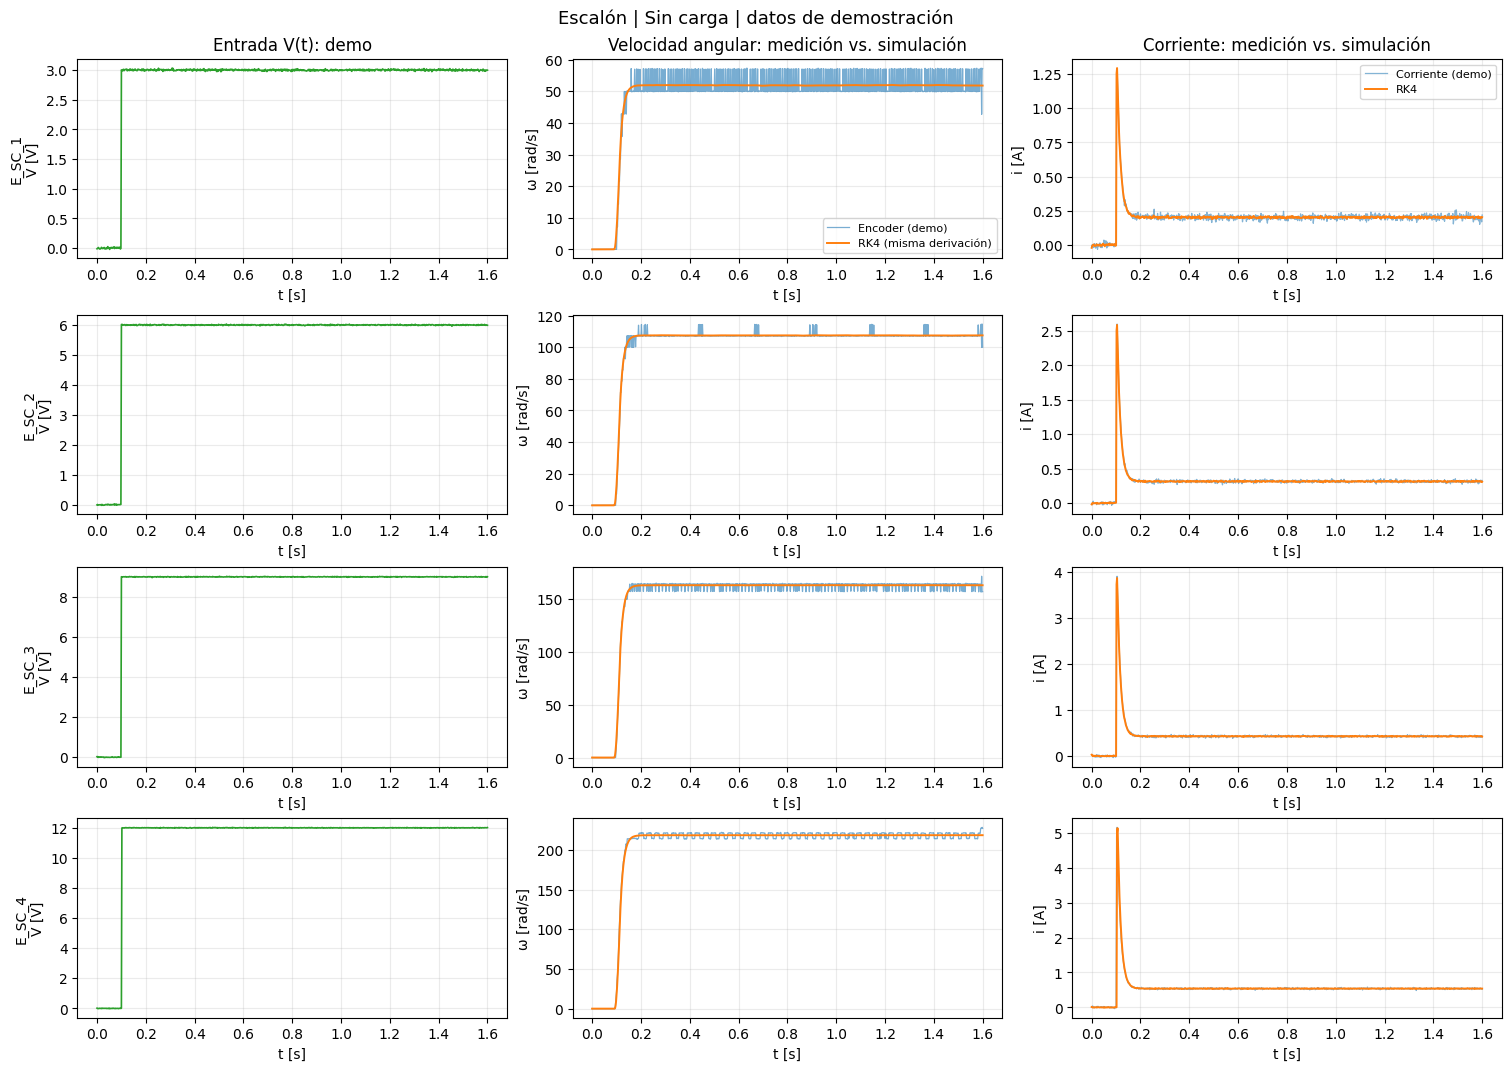

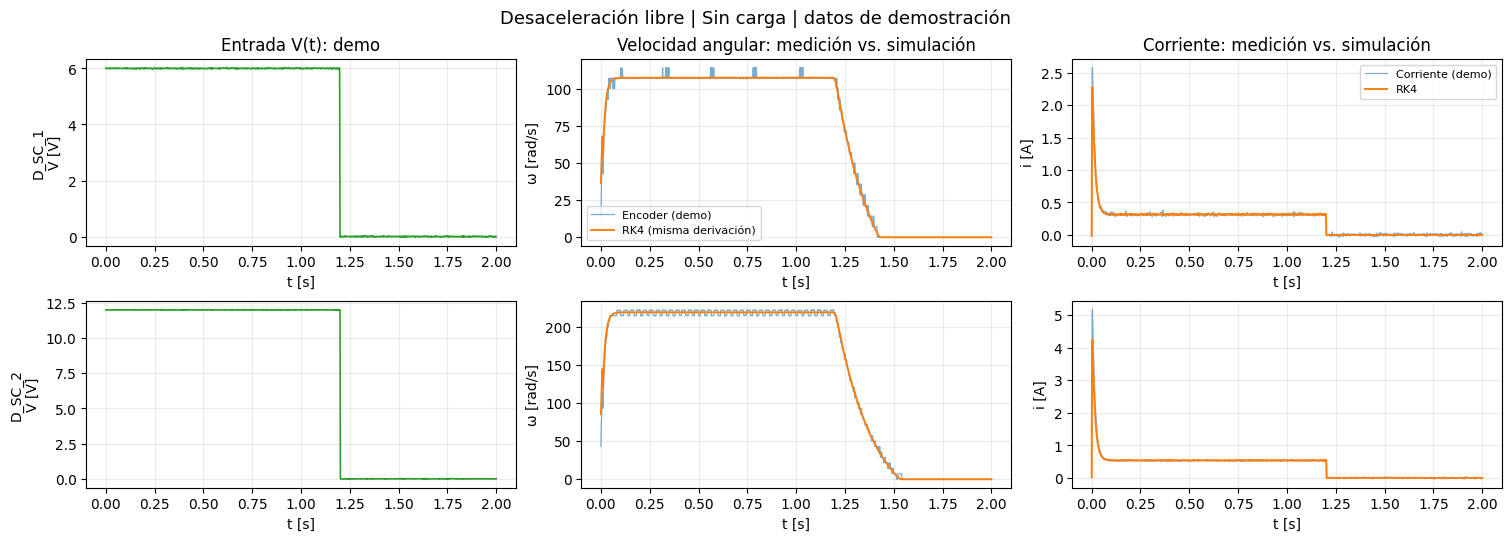

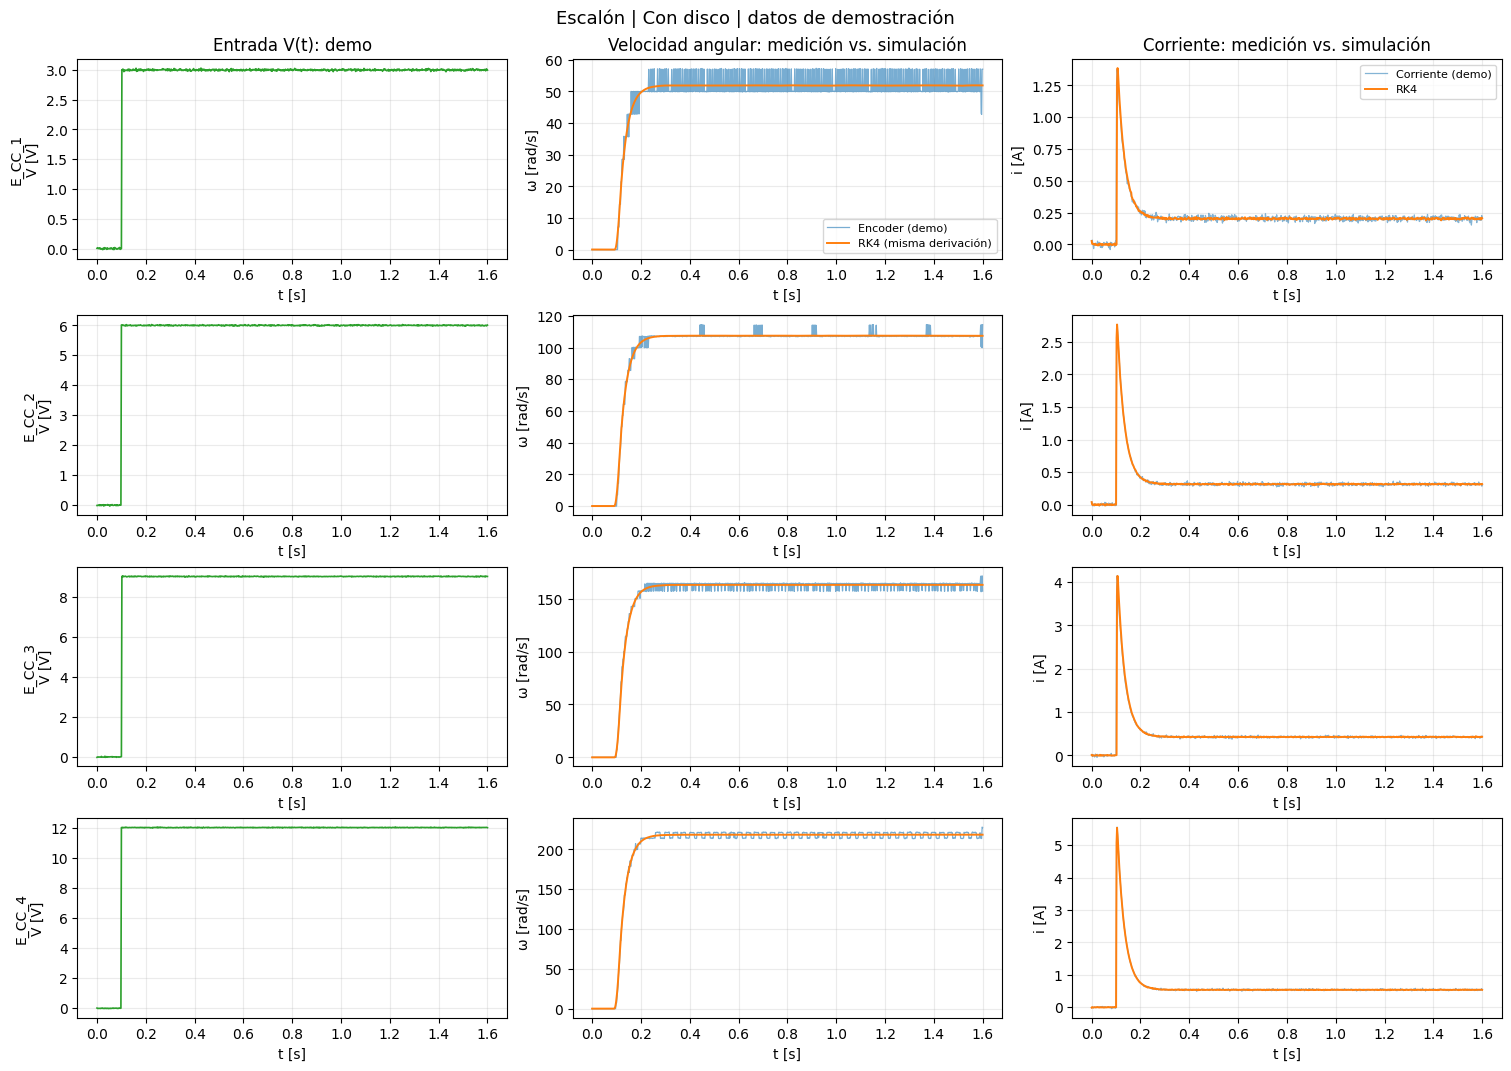

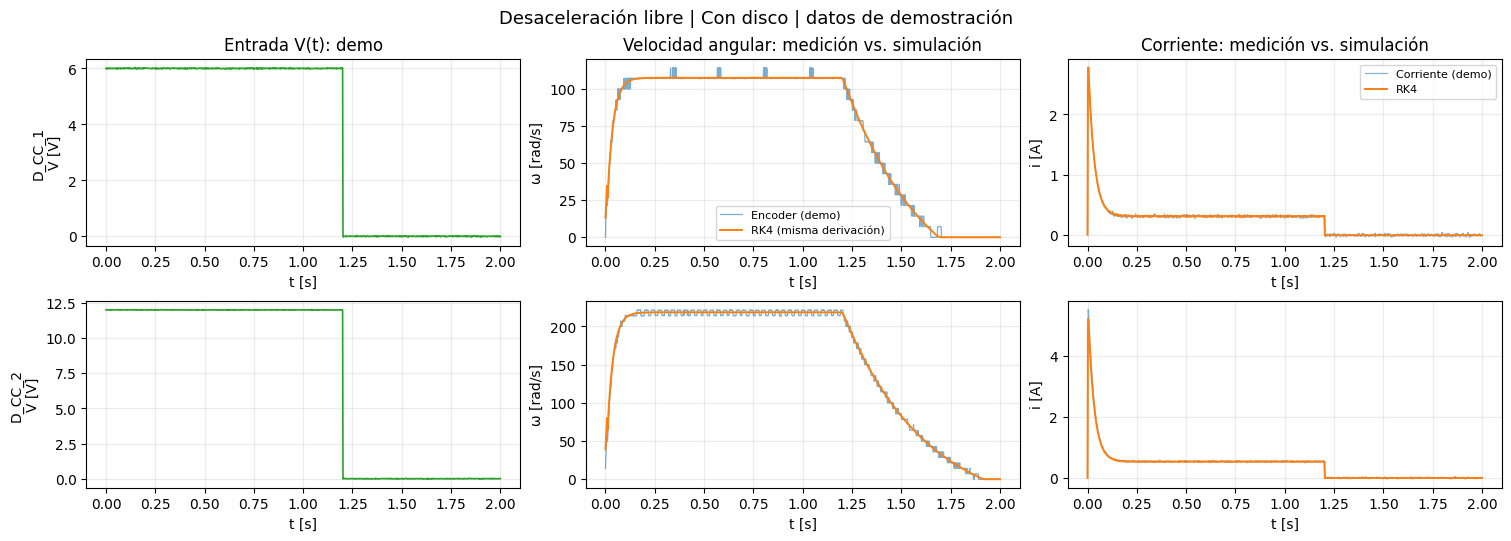

In [22]:
def graficar_comparaciones_gemelo(resultados, indicadores):
    for (carga, tipo), grupo in indicadores.groupby(["Carga", "Tipo"], sort=False):
        ids = list(grupo.index)
        fig, ejes = plt.subplots(len(ids), 3, figsize=(15, 2.65 * len(ids)),
                                 squeeze=False, constrained_layout=True)
        for fila, id_ in enumerate(ids):
            d = resultados[id_]
            t = d["t"].to_numpy()
            a_V, a_w, a_i = ejes[fila]
            a_V.plot(t, d["V_med"], color="tab:green", lw=1.2)
            a_V.set_ylabel(f"{id_}\nV [V]")
            a_w.plot(t, d["omega_med"], color="tab:blue", alpha=0.60,
                     lw=0.9, label="Encoder (demo)" if usar_demo else "Encoder medido")
            a_w.plot(t, d["omega_sim_encoder"], color="tab:orange",
                     lw=1.4, label="RK4 (misma derivación)")
            a_w.set_ylabel("ω [rad/s]")
            a_i.plot(t, d["i_med"], color="tab:blue", alpha=0.55,
                     lw=0.9, label="Corriente (demo)" if usar_demo else "Corriente medida")
            a_i.plot(t, d["i_sim"], color="tab:orange", lw=1.4, label="RK4")
            a_i.set_ylabel("i [A]")
            for a in (a_V, a_w, a_i):
                a.set_xlabel("t [s]")
                a.grid(alpha=0.25)
        ejes[0, 0].set_title("Entrada V(t): demo" if usar_demo else "Entrada V(t) registrada")
        ejes[0, 1].set_title("Velocidad angular: medición vs. simulación")
        ejes[0, 2].set_title("Corriente: medición vs. simulación")
        ejes[0, 1].legend(loc="best", fontsize=8)
        ejes[0, 2].legend(loc="best", fontsize=8)
        fig.suptitle(f"{tipo} | {carga} | {'datos de demostración' if usar_demo else 'datos reales'}", fontsize=13)
        plt.show()


graficar_comparaciones_gemelo(resultados_gemelo, tabla_gemelo)


### Síntesis de la comparación

El error de corriente se calcula directamente con las lecturas del sensor. En velocidad, la comparación principal utiliza la derivación de posición con la misma ventana para datos experimentales y simulados, evitando atribuir al modelo diferencias causadas exclusivamente por el filtrado de la señal. El valor $R^2$ y los errores normalizados permiten comparar el desempeño entre pruebas con diferentes escalones y cargas.

La cuantización del encoder afecta especialmente las velocidades bajas; también pueden intervenir fricción estática no representada por $\tanh(\omega/\varepsilon)$, errores en $K_e$, $K_t$, $b$, $\tau_c$ y la aproximación del estado inicial. En las desaceleraciones, la distinción entre circuito abierto y frenado eléctrico depende del comportamiento de la corriente medida tras el corte. Los errores mostrados incluyen tanto las limitaciones del modelo como el ruido y la incertidumbre de las mediciones.

In [23]:
resumen_gemelo = (tabla_gemelo.groupby(["Tipo", "Carga"], sort=False)
                  [["RMSE ω [rad/s]", "NRMSE ω [%]", "RMSE i [A]", "NRMSE i [%]"]]
                  .mean().round(4))
display(resumen_gemelo)

peor_w = tabla_gemelo["RMSE ω [rad/s]"].idxmax()
peor_i = tabla_gemelo["RMSE i [A]"].idxmax()
print(f"Mayor RMSE de velocidad: {peor_w} ({tabla_gemelo.loc[peor_w, 'RMSE ω [rad/s]']:.4f} rad/s).")
print(f"Mayor RMSE de corriente: {peor_i} ({tabla_gemelo.loc[peor_i, 'RMSE i [A]']:.4f} A).")
print("Las cifras corresponden a datos simulados con ruido y cuantización." if usar_demo
      else "Las cifras corresponden a los datos experimentales cargados del Excel.")


,,RMSE ω [rad/s],NRMSE ω [%],RMSE i [A],NRMSE i [%]
Tipo,Carga,,,,
Escalón,Sin carga,2.7589,2.5483,0.0563,11.7808
Desaceleración libre,Sin carga,3.0755,1.8574,0.0498,9.9915
Escalón,Con disco,2.7366,2.5367,0.0532,10.0528
Desaceleración libre,Con disco,2.8439,1.7784,0.0288,4.61


Mayor RMSE de velocidad: D_SC_2 (4.1936 rad/s).
Mayor RMSE de corriente: E_SC_4 (0.1775 A).
Las cifras corresponden a datos simulados con ruido y cuantización.


## **Simulación (Euler y RK4)**

Notitas y sugerencias:   

Una subsección por método, más la de estabilidad (paso máximo de Euler contra L/R).

Estimación de parámetros (Ke, Kt, J, b, τc). Una subsección por parámetro, con la tabla final.

## **Control PID**

In [24]:
## **Control PID**


## **Simulación Interfáz**

## **Preguntas obligatorias**
1. ¿Qué paso máximo permite Euler explícito antes de volverse
inestable y cómo se relaciona con L/R?   

2. ¿Cuánto cambia el desempeño del PID real si el
término derivativo usa diferencias hacia atrás crudas en lugar de una derivada filtrada? 

3. ¿Qué parámetro del modelo explica la mayor discrepancia entre el gemelo digital y el motor real
a bajas velocidades? ¿Qué fracción de la energía eléctrica se convierte en trabajo mecánico
útil?

## **Conclusiones**

## Extensión - (si nos da tiempo sino borrar)
Implementen el control de posición de un brazo de un grado de libertad
(péndulo invertido parcial o brazo con carga) y comparen PID contra una estrategia con
prealimentación basada en su modelo.

## **8. USO DE IA**

**Herramienta:** Claude (Anthropic), usado para depurar, redactar y explorar ideas. La planificación del problema se hizo antes de programar.

**Principales prompts y para qué se usaron**

| Prompt (resumen) | Para qué se usó |
| :--- | :--- |
| "Puedes dar una idea de la estructura para el excel de las mediciones" | Sugerencias de organización para agilizar la toma de datos en las mediciones |
| "Puedes ayudarme generando un archivo Demo que de datos de prueba"| Se explicó como añadir la función Usar Demo para agregar los datos de demostración siguientdo el excel de mediciones|
| - |- |